# Model Training 1: Linear Regression

In [42]:
# imports
import pandas as pd
from sklearn.linear_model import LinearRegression
import matplotlib.pyplot as plt
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np
import seaborn as sns
import joblib

In [2]:
# function to plot model evaluation
sns.set_theme(style="whitegrid")

def plot_model_evaluation(y_true, y_pred, title="Model Evaluation"):
    """
    Plot residual, prediction, and ground truth diagnostics for regression models using 1-year bins.
    
    Parameters:
        y_true (array-like): Ground truth values in days
        y_pred (array-like): Model predictions in days
        title (str): Title of the overall plot
    """
    y_true = np.array(y_true).flatten()
    y_pred = np.array(y_pred).flatten()
    residuals = y_pred - y_true

    # Define 1-year bin size in days
    bin_size = 365

    # Determine the range for each dataset
    max_residual = np.max(residuals)
    min_residual = np.min(residuals)
    max_value = max(np.max(y_true), np.max(y_pred))

    # Calculate number of bins
    bins_residuals = np.arange(min_residual, max_residual + bin_size, bin_size)
    bins_values = np.arange(0, max_value + bin_size, bin_size)

    # Create figure layout
    fig, axs = plt.subplots(3, 2, figsize=(14, 14))
    fig.suptitle(title, fontsize=16)

    # 1. Residual Histogram
    sns.histplot(residuals, bins=bins_residuals, ax=axs[0, 0], color="C0", stat="count")
    axs[0, 0].set_title("Residual Histogram")
    axs[0, 0].set_xlabel("Residual (days)")
    axs[0, 0].set_ylabel("Density")

    # 2. Ground Truth Histogram
    sns.histplot(y_true, bins=bins_values, ax=axs[0, 1], color="C0", stat="count")
    axs[0, 1].set_title("Ground Truth Histogram")
    axs[0, 1].set_xlabel("Ground Truth (days)")
    axs[0, 1].set_ylabel("Density")

    # 3. Prediction Histogram
    sns.histplot(y_pred, bins=bins_values, ax=axs[1, 0], color="C0", stat="count")
    axs[1, 0].set_title("Prediction Histogram")
    axs[1, 0].set_xlabel("Prediction (days)")
    axs[1, 0].set_ylabel("Density")

    # 4. Ground Truth vs Predictions (binned)
    df_gt_pred = pd.DataFrame({"ground_truth": y_true, "prediction": y_pred})
    df_gt_pred["gt_bin"] = pd.cut(df_gt_pred["ground_truth"], bins=bins_values)
    binned_gt = df_gt_pred.groupby("gt_bin", observed=False).mean(numeric_only=True)

    axs[1, 1].plot(binned_gt["ground_truth"], binned_gt["prediction"], label="Prediction", color="darkorange")
    axs[1, 1].plot(binned_gt["ground_truth"], binned_gt["ground_truth"], linestyle="--", color="C0", label="Ideal")
    axs[1, 1].set_title("Ground Truth vs Predictions")
    axs[1, 1].set_xlabel("Ground Truth (days)")
    axs[1, 1].set_ylabel("Prediction (days)")
    axs[1, 1].legend()

    # 5. Predictions vs Residual (binned)
    df_pred_res = pd.DataFrame({"prediction": y_pred, "residual": residuals})
    df_pred_res["pred_bin"] = pd.cut(df_pred_res["prediction"], bins=bins_values)
    binned_pred = df_pred_res.groupby("pred_bin", observed=False).mean(numeric_only=True)

    axs[2, 0].plot(binned_pred["prediction"], binned_pred["residual"], color="darkorange")
    axs[2, 0].axhline(0, linestyle="--", color="C0")
    axs[2, 0].set_title("Predictions vs Residual")
    axs[2, 0].set_xlabel("Prediction (days)")
    axs[2, 0].set_ylabel("Residual (days)")

    # 6. Ground Truth vs Residual (binned)
    df_gt_res = pd.DataFrame({"ground_truth": y_true, "residual": residuals})
    df_gt_res["gt_bin"] = pd.cut(df_gt_res["ground_truth"], bins=bins_values)
    binned_gt_res = df_gt_res.groupby("gt_bin", observed=False).mean(numeric_only=True)

    axs[2, 1].plot(binned_gt_res["ground_truth"], binned_gt_res["residual"], color="darkorange")
    axs[2, 1].axhline(0, linestyle="--", color="C0")
    axs[2, 1].set_title("Ground Truth vs Residual")
    axs[2, 1].set_xlabel("Ground Truth (days)")
    axs[2, 1].set_ylabel("Residual (days)")

    plt.tight_layout(rect=[0, 0.03, 1, 0.95])
    plt.show()

In [3]:
# function for analyzing RMSE, MAE, and R² for different remaining lifetime ranges
def split_metrics_analysis(y_true, y_pred, threshold=2000):
    """
    Compute RMSE, MAE, and R² separately for low and high remaining lifetimes.
    
    Parameters:
    - y_true: true values (array-like or pandas Series)
    - y_pred: predicted values (array-like or pandas Series)
    - threshold: cutoff value for binning (default is 2000)
    
    Returns:
    - Dictionary with RMSE, MAE, and R² for below and above the threshold
    """
    
    # Ensure arrays
    y_true = np.array(y_true).flatten()
    y_pred = np.array(y_pred).flatten()

    # Create masks
    mask_low = y_true <= threshold
    mask_high = y_true > threshold

    # Compute metrics for low remaining lifetimes
    rmse_low = np.sqrt(mean_squared_error(y_true[mask_low], y_pred[mask_low]))
    mae_low = mean_absolute_error(y_true[mask_low], y_pred[mask_low])
    r2_low = r2_score(y_true[mask_low], y_pred[mask_low])

    # Compute metrics for high remaining lifetimes
    rmse_high = np.sqrt(mean_squared_error(y_true[mask_high], y_pred[mask_high]))
    mae_high = mean_absolute_error(y_true[mask_high], y_pred[mask_high])
    r2_high = r2_score(y_true[mask_high], y_pred[mask_high])
    
    return {
        "RMSE_low": rmse_low, "MAE_low": mae_low, "R2_low": r2_low,
        "RMSE_high": rmse_high, "MAE_high": mae_high, "R2_high": r2_high
    }

In [51]:
# function to calculate evaluation metrics for thresholds
def calculate_threshold_metrics(y_test, y_pred):
    """
    Calculate evaluation metrics for thresholds of 1 year, 5 years, and 25 years.
    
    Parameters:
    - y_test: Ground truth values.
    - y_pred: Predicted values.
    
    Returns:
    - A pandas DataFrame containing the evaluation metrics for each threshold.
    """
    import pandas as pd

    thresholds = [365, 5 * 365, 25 * 365]
    results_dict = {
        "Metric": ["RMSE Below", "MAE Below", "R² Below", "RMSE Above", "MAE Above", "R² Above"]
    }

    for threshold in thresholds:
        results = split_metrics_analysis(y_test, y_pred, threshold=threshold)
        results_dict[f"Threshold {threshold} days"] = [
            results['RMSE_low'],
            results['MAE_low'],
            results['R2_low'],
            results['RMSE_high'],
            results['MAE_high'],
            results['R2_high']
        ]

    results_df = pd.DataFrame(results_dict)
    return results_df

## 1. Baseline Linear Regression for Lifetime

In [4]:
# read data
train_df = pd.read_csv("../Data/ModelInput/TrainPreprocessed.csv")
test_df = pd.read_csv("../Data/ModelInput/TestPreprocessed.csv")

In [5]:
# separate features and label
X_train1 = train_df.drop(columns=["LIFETIME", "REMAINING_LIFETIME"])
y_train1 = train_df["LIFETIME"]

X_test1 = test_df.drop(columns=["LIFETIME", "REMAINING_LIFETIME"])
y_test1 = test_df["LIFETIME"]

In [6]:
# train linear regressor
model1 = LinearRegression()
model1.fit(X_train1, y_train1)

LinearRegression()

In [7]:
# predict
y_pred1 = model1.predict(X_test1)

In [55]:
# evaluate
print(f"Linear Regression Results:")
print(f"MAE: {mean_absolute_error(y_test1, y_pred1):.2f}")
print(f"RMSE: {np.sqrt(mean_squared_error(y_test1, y_pred1)):.2f}")
print(f"R² Score: {r2_score(y_test1, y_pred1):.2f}")

Linear Regression Results:
MAE: 448.69
RMSE: 894.55
R² Score: 0.96


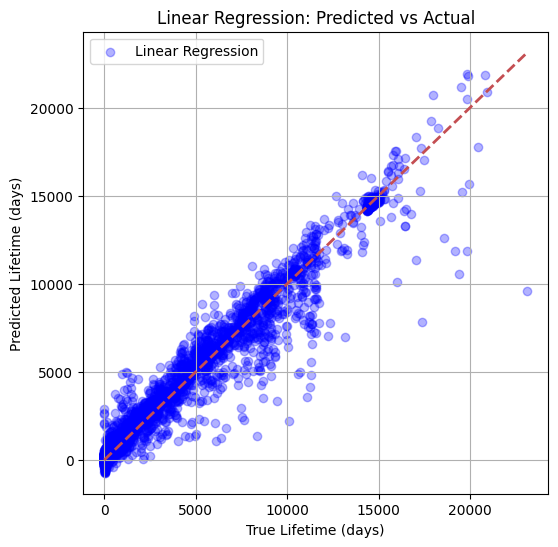

In [10]:
# visualize evaluation
plt.style.use('default')
plt.figure(figsize=(6, 6))
plt.scatter(y_test1, y_pred1, alpha=0.3, label="Linear Regression", color="blue")
plt.xlabel("True Lifetime (days)")
plt.ylabel("Predicted Lifetime (days)")
plt.title("Linear Regression: Predicted vs Actual")
plt.plot([y_test1.min(), y_test1.max()], [y_test1.min(), y_test1.max()], 'r--', lw=2)
plt.legend()
plt.grid(True)
plt.show()

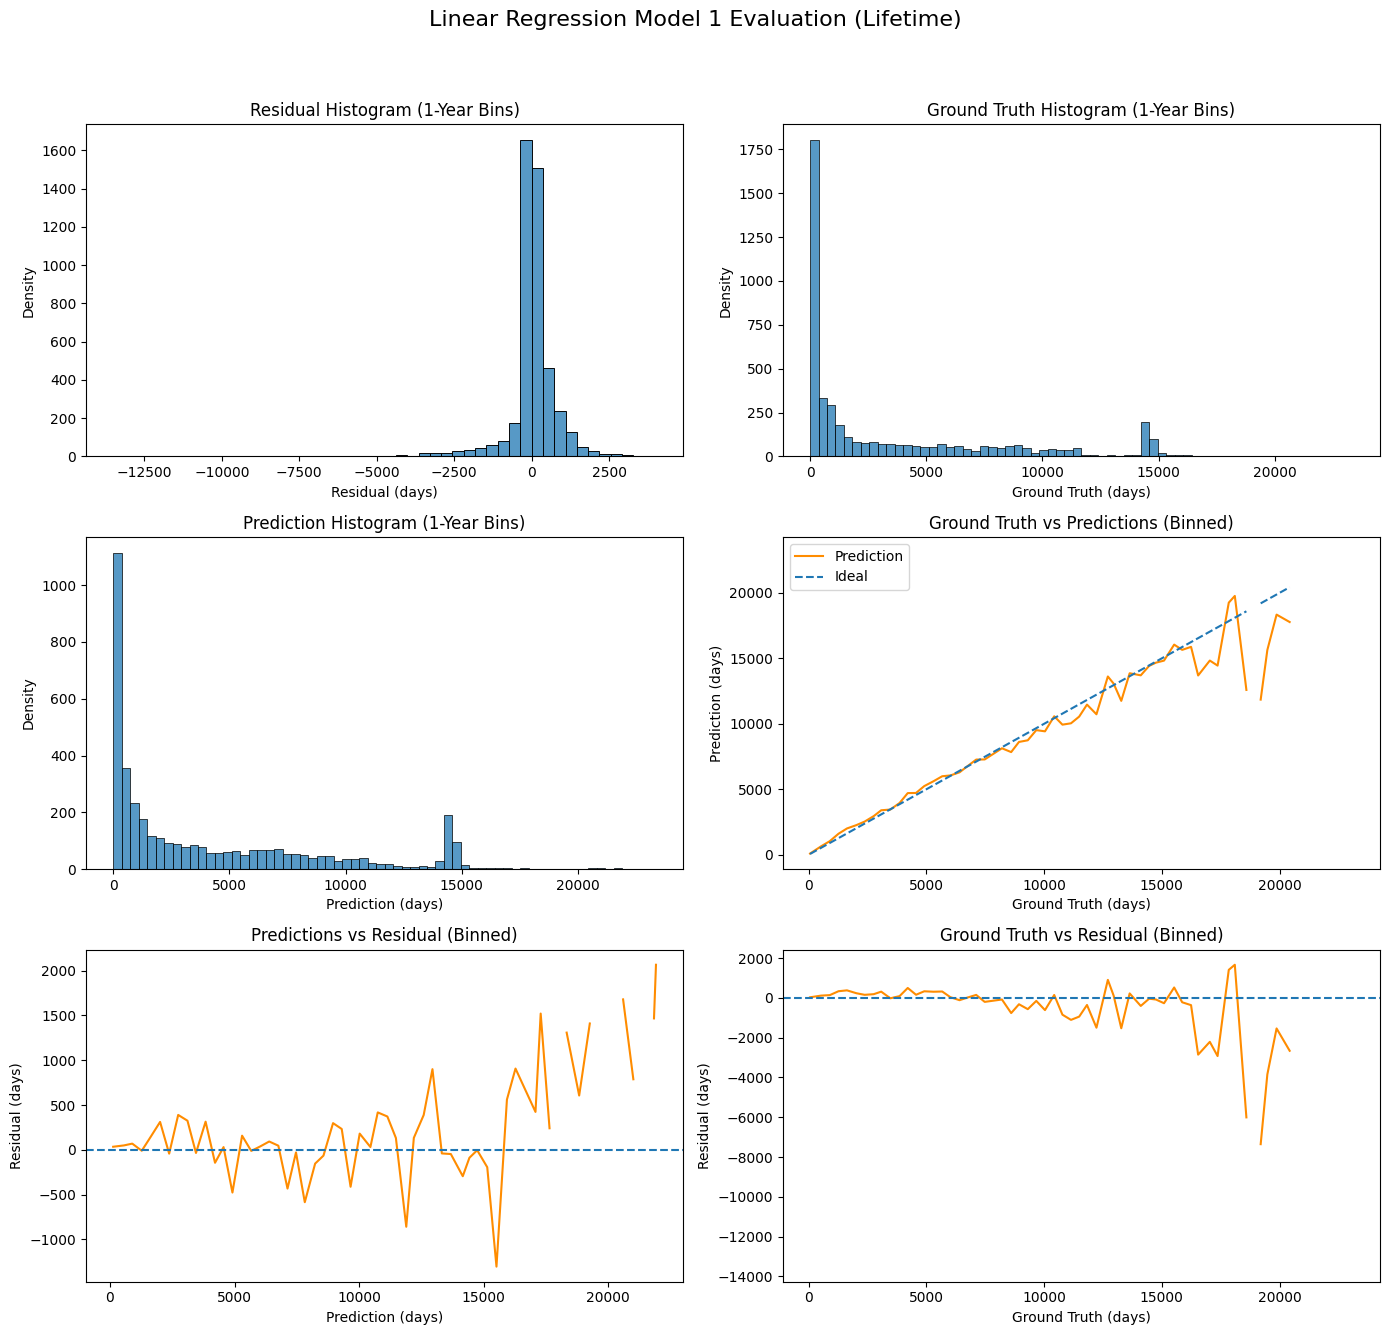

In [11]:
plot_model_evaluation(y_test1, y_pred1, title="Linear Regression Model 1 Evaluation (Lifetime)") 

In [ ]:
# evaluate below and above thresholds of 1 year, 5 years, and 25 years
print(calculate_threshold_metrics(y_test1, y_pred1))

       Metric  Threshold 365 days  Threshold 1825 days  Threshold 9125 days
0  RMSE Below          251.516494           394.811867           697.035342
1   MAE Below          146.617476           212.698536           385.290650
2    R² Below           -7.951584             0.299979             0.926608
3  RMSE Above         1128.908482          1313.708630          1625.824296
4   MAE Above          643.059376           787.686326           820.372970
5    R² Above            0.947021             0.910650             0.533880


## 2. Baseline Linear Regression for Remaining Lifetime

In [43]:
# save model
joblib.dump(model1, "../Models/LinReg1.pkl")

['../Models/LinReg1.pkl']

In [12]:
# separate features and label
X_train2 = train_df.drop(columns=["LIFETIME", "REMAINING_LIFETIME"])
y_train2 = train_df["REMAINING_LIFETIME"]

X_test2 = test_df.drop(columns=["LIFETIME", "REMAINING_LIFETIME"])
y_test2 = test_df["REMAINING_LIFETIME"]

In [44]:
# train linear regressor
model2 = LinearRegression()
model2.fit(X_train2, y_train2)

LinearRegression()

In [45]:
# predict
y_pred2 = model2.predict(X_test2)

LinearRegression()

In [46]:
# evaluate
print(f"Linear Regression Results:")
print(f"MAE: {mean_absolute_error(y_test2, y_pred2):.2f}")
print(f"RMSE: {np.sqrt(mean_squared_error(y_test2, y_pred2)):.2f}")
print(f"R² Score: {r2_score(y_test2, y_pred2):.2f}")

Linear Regression Results:
MAE: 448.69
RMSE: 894.55
R² Score: 0.39


In [56]:
# visualize evaluation
plt.style.use('default')
plt.figure(figsize=(6, 6))
plt.scatter(y_test2, y_pred2, alpha=0.3, label="Linear Regression", color="blue")
plt.xlabel("True Remaining Lifetime (days)")
plt.ylabel("Predicted Remaining Lifetime (days)")
plt.title("Linear Regression: Predicted vs Actual")
plt.plot([y_test2.min(), y_test2.max()], [y_test2.min(), y_test2.max()], 'r--', lw=2)
plt.legend()
plt.grid(True)
plt.show()

Linear Regression Results:
MAE: 448.69
RMSE: 894.55
R² Score: 0.39


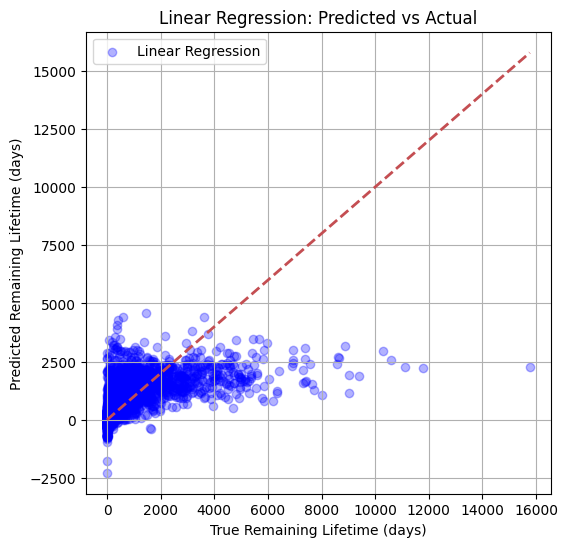

In [57]:
plot_model_evaluation(y_test2, y_pred2, title="Linear Regression Model 2 Evaluation (Remaining Lifetime)")

In [61]:
# evaluate below and above thresholds of 1 year, 5 years, and 25 years
print(calculate_threshold_metrics(y_test2, y_pred2))

       Metric  Threshold 365 days  Threshold 1825 days  Threshold 9125 days
0  RMSE Below          439.356361           537.485814           828.721496
1   MAE Below          245.054273           319.226056           437.362482
2    R² Below          -25.379688            -0.878140             0.402494
3  RMSE Above         1552.547242          2497.009131          9367.726118
4   MAE Above          988.693253          1824.700025          9128.937631
5    R² Above            0.108658            -0.943178           -19.962891


In [60]:
# save model
joblib.dump(model2, "../Models/LinReg2.pkl")

['../Models/LinReg2.pkl']